# Video Game Sales: Exploratory Data Analysis

This dataset comes from Kaggle (scraped from vgchartz.com) and lists video games that sold more than 100,000 copies. It has 16,598 games and 11 columns: name, platform, release year, genre, publisher, and regional sales (NA, EU, JP, Other, Global).

**Questions I want to answer:**
- Which genres and platforms sell the most?
- How has the industry changed over the years?
- How different is player taste across regions?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [2]:
df = pd.read_csv("/content/vgsales.csv")
print("Shape:", df.shape)
df.head()

Shape: (16598, 11)


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [3]:
print("Shape:", df.shape)
print("\nDtypes:\n", df.dtypes)
print("\nMemory usage (MB):", round(df.memory_usage(deep=True).sum() / 1024**2, 2))
df.info()

Shape: (16598, 11)

Dtypes:
 Rank              int64
Name             object
Platform         object
Year            float64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object

Memory usage (MB): 4.74
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64


The dataset has 16,598 rows and 11 columns, with a mix of text columns (Name, Platform, Genre, Publisher) and numeric columns (Rank, Year and the five sales columns). It uses about 4.74 MB of memory, which is small enough to work with easily. Year is stored as a float instead of an integer because it contains missing values, and Year and Publisher have fewer non-null entries than the other columns, so I will check them in the missing values section.

In [4]:
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [5]:
df.tail()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.0,0.0,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.0,0.0,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.0,0.0,0.01
16596,16599,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.0,0.0,0.01
16597,16600,Spirits & Spells,GBA,2003.0,Platform,Wanadoo,0.01,0.00,0.0,0.0,0.01


           missing  percent
Year           271     1.63
Publisher       58     0.35


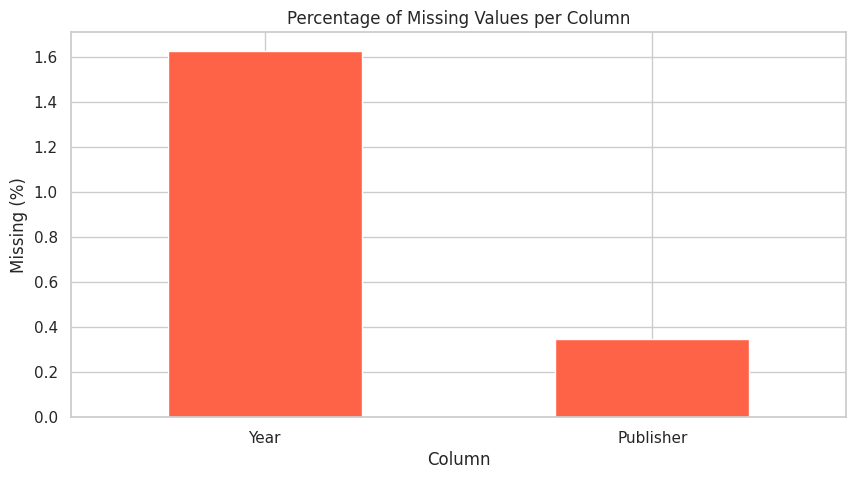

In [6]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"missing": missing, "percent": missing_pct})
missing_df = missing_df[missing_df.missing > 0].sort_values("missing", ascending=False)
print(missing_df)

missing_df["percent"].plot(kind="bar", color="tomato")
plt.title("Percentage of Missing Values per Column")
plt.xlabel("Column")
plt.ylabel("Missing (%)")
plt.xticks(rotation=0)
plt.show()

Only two columns have missing values: Year (271 rows, about 1.63%) and Publisher (58 rows, about 0.35%). Both are small shares of the 16,598 rows. My guess is that these are older or lesser-known games where the release year or publisher was never recorded on the source website (vgchartz.com).

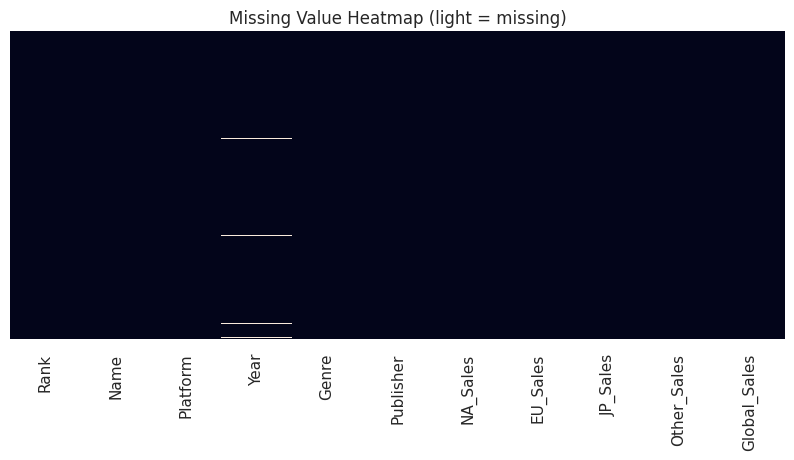

In [7]:
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Value Heatmap (light = missing)")
plt.show()

The heatmap shows that the missing values are scattered across the dataset rather than concentrated in one block, and they are limited to a small portion of the rows.

In [8]:
print("Before:", df.shape)

df = df.dropna(subset=["Year"]).copy()
df["Year"] = df["Year"].astype(int)
df["Publisher"] = df["Publisher"].fillna("Unknown")

print("After:", df.shape)
print("Missing left?\n", df.isnull().sum())

Before: (16598, 11)
After: (16327, 11)
Missing left?
 Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64


I dropped the 271 rows with a missing Year (about 1.6% of the data), since a trend over time can't be built without it, leaving 16,327 rows. For Publisher, I filled missing values with "Unknown" so no rows were lost.

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Rank,16327.0,8292.868194,4792.669778,1.00,4136.50,8295.00,12441.50,16600.00
Year,16327.0,2006.406443,5.828981,1980.00,2003.00,2007.00,2010.00,2020.00
NA_Sales,16327.0,0.265415,0.821591,0.00,0.00,0.08,0.24,41.49
EU_Sales,16327.0,0.147554,0.508766,0.00,0.00,0.02,0.11,29.02
JP_Sales,16327.0,0.078661,0.311557,0.00,0.00,0.00,0.04,10.22
Other_Sales,16327.0,0.048325,0.189885,0.00,0.00,0.01,0.04,10.57
Global_Sales,16327.0,0.540232,1.565732,0.01,0.06,0.17,0.48,82.74


The mean of Global_Sales is 0.54 million while the median is 0.17 million. Since the mean is much higher than the median, a few blockbuster games pull the average up, so the data is right-skewed. The largest seller reached 82.74 million.

In [10]:
for col in ["Platform", "Genre", "Publisher"]:
    print(f"\n--- {col} (top 10) ---")
    print(df[col].value_counts().head(10))


--- Platform (top 10) ---
Platform
DS      2133
PS2     2127
PS3     1304
Wii     1290
X360    1235
PSP     1197
PS      1189
PC       943
GBA      811
XB       803
Name: count, dtype: int64

--- Genre (top 10) ---
Genre
Action          3253
Sports          2304
Misc            1710
Role-Playing    1471
Shooter         1282
Adventure       1276
Racing          1226
Platform         876
Simulation       851
Fighting         836
Name: count, dtype: int64

--- Publisher (top 10) ---
Publisher
Electronic Arts                 1339
Activision                       966
Namco Bandai Games               928
Ubisoft                          918
Konami Digital Entertainment     823
THQ                              712
Nintendo                         696
Sony Computer Entertainment      682
Sega                             632
Take-Two Interactive             412
Name: count, dtype: int64


Action is the most common genre (3,253 games). DS has the most games among platforms (2,133), just ahead of PS2 (2,127). Electronic Arts is the most frequent publisher (1,339 games).

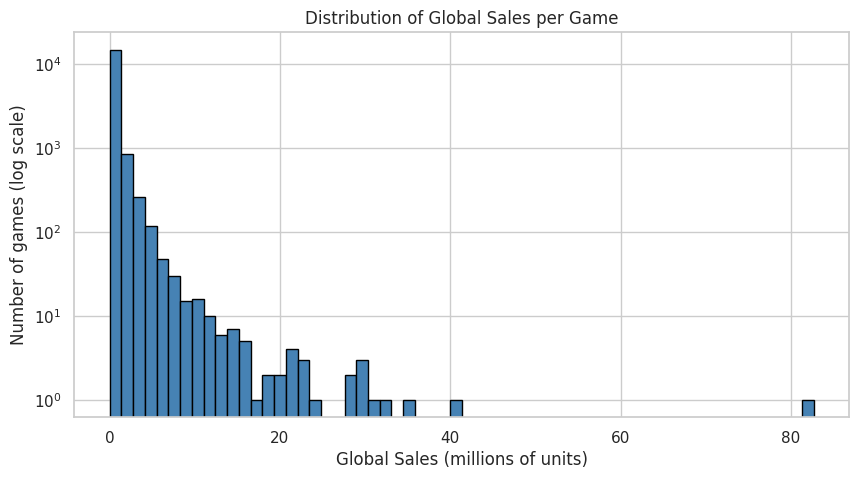

In [11]:
plt.hist(df["Global_Sales"], bins=60, color="steelblue", edgecolor="black")
plt.yscale("log")
plt.title("Distribution of Global Sales per Game")
plt.xlabel("Global Sales (millions of units)")
plt.ylabel("Number of games (log scale)")
plt.show()

About 87.4% of games sold under 1 million copies, and the mean (0.54M) is more than three times the median (0.17M), so the distribution is strongly right-skewed. A log scale on the y-axis keeps the rare high-selling games visible.

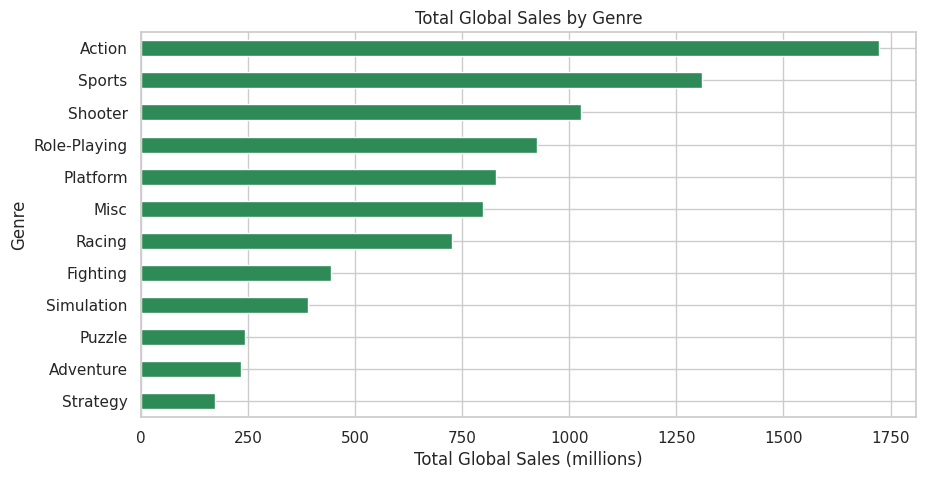

In [12]:
genre_sales = df.groupby("Genre")["Global_Sales"].sum().sort_values()
genre_sales.plot(kind="barh", color="seagreen")
plt.title("Total Global Sales by Genre")
plt.xlabel("Total Global Sales (millions)")
plt.ylabel("Genre")
plt.show()

Action has the highest total sales (about 1,723M), followed by Sports (about 1,309M) and Shooter (about 1,026M).

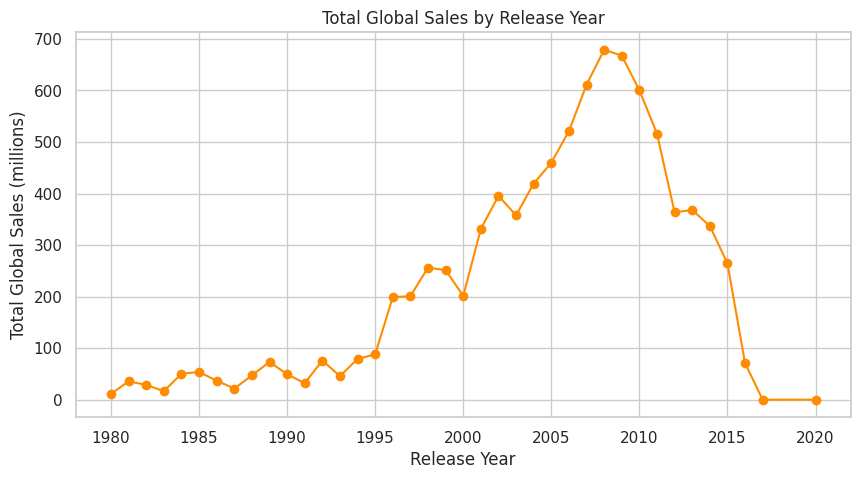

In [13]:
yearly = df.groupby("Year")["Global_Sales"].sum()
yearly.plot(marker="o", color="darkorange")
plt.title("Total Global Sales by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Total Global Sales (millions)")
plt.show()

Total sales rose steadily from the late 1990s and peaked in 2008 at roughly 680 million units, then declined in the following years. The near-zero values for 2017 and 2020 are most likely due to incomplete data, since very few games are recorded for those years.

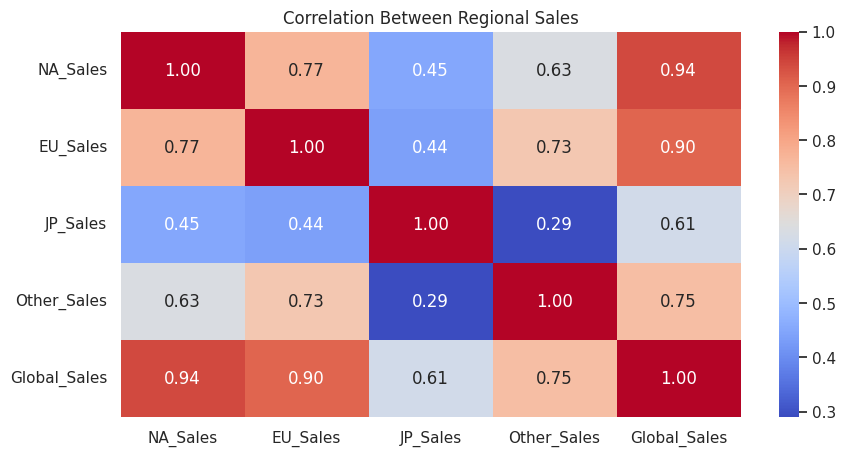

In [14]:
sales_cols = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]
sns.heatmap(df[sales_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Regional Sales")
plt.show()

Global_Sales is most strongly correlated with NA_Sales (0.94) and EU_Sales (0.90), and less so with JP_Sales (0.61). Japan also has the weakest correlation with the other regions (0.29 to 0.45), which suggests its market behaves differently from the rest.

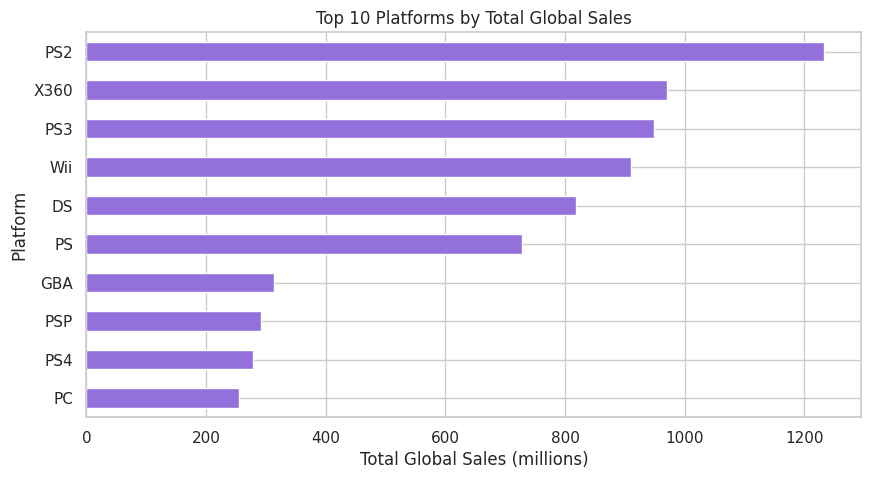

In [15]:
top_platforms = df.groupby("Platform")["Global_Sales"].sum().nlargest(10).sort_values()
top_platforms.plot(kind="barh", color="mediumpurple")
plt.title("Top 10 Platforms by Total Global Sales")
plt.xlabel("Total Global Sales (millions)")
plt.ylabel("Platform")
plt.show()

PS2 is the best-selling platform (about 1,234M), ahead of X360 (about 970M) and PS3 (about 949M).

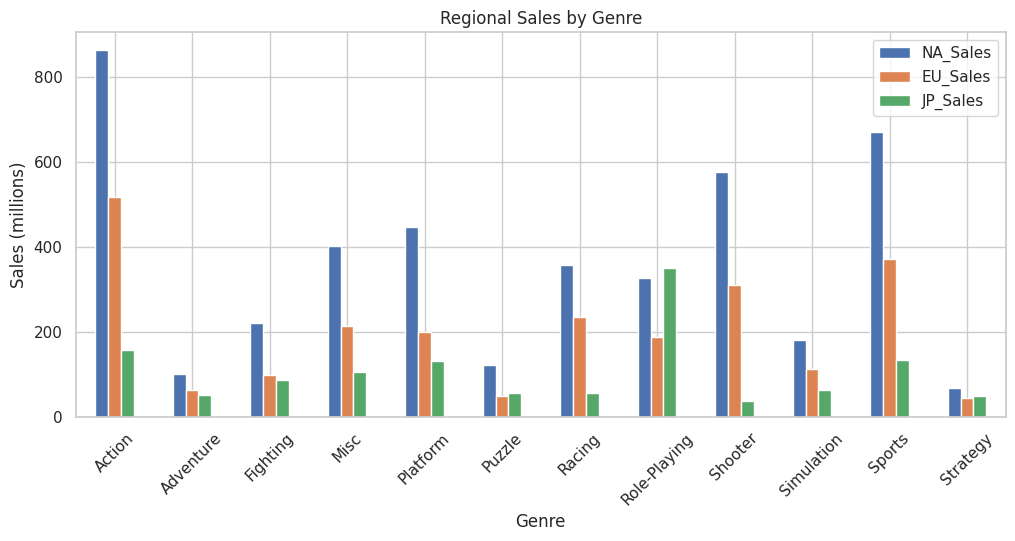

In [16]:
region_genre = df.groupby("Genre")[["NA_Sales", "EU_Sales", "JP_Sales"]].sum()
region_genre.plot(kind="bar", figsize=(12, 5))
plt.title("Regional Sales by Genre")
plt.xlabel("Genre")
plt.ylabel("Sales (millions)")
plt.xticks(rotation=45)
plt.show()

Role-Playing is the top genre in Japan, while Action leads in North America, so Japanese players' taste differs from the West.

In [17]:
print("Top genre by sales:\n", df.groupby("Genre")["Global_Sales"].sum().nlargest(3).round(1))
print("\nTop platform by sales:\n", df.groupby("Platform")["Global_Sales"].sum().nlargest(3).round(1))
print("\nPeak year:", df.groupby("Year")["Global_Sales"].sum().idxmax())
print("\nMean vs median Global_Sales:", round(df["Global_Sales"].mean(), 2), "vs", df["Global_Sales"].median())
print("\nGames under 1M sales (%):", round((df["Global_Sales"] < 1).mean() * 100, 1))
print("\nTop genre in Japan:", df.groupby("Genre")["JP_Sales"].sum().idxmax())
print("Top genre in NA:", df.groupby("Genre")["NA_Sales"].sum().idxmax())

Top genre by sales:
 Genre
Action     1722.9
Sports     1309.2
Shooter    1026.2
Name: Global_Sales, dtype: float64

Top platform by sales:
 Platform
PS2     1233.5
X360     969.6
PS3      949.4
Name: Global_Sales, dtype: float64

Peak year: 2008

Mean vs median Global_Sales: 0.54 vs 0.17

Games under 1M sales (%): 87.4

Top genre in Japan: Role-Playing
Top genre in NA: Action


## Key Findings

1. Action (about 1,723M), Sports (about 1,309M) and Shooter (about 1,026M) are the top three genres by global sales.
2. PS2 (about 1,234M), X360 (about 970M) and PS3 (about 949M) are the top three platforms.
3. 2008 had the highest total global sales of any release year.
4. Sales are highly right-skewed: the mean is 0.54M vs a median of 0.17M, and 87.4% of games sold under 1 million copies.
5. Japan's top genre is Role-Playing, while North America's is Action, so regional taste clearly differs.